# 08 - Land Signals

**Owner:** Mostafa Elsherif
**Input:** `data/processed/master_monthly.csv` (from notebook 07) and `data/processed/landsat_yearly.csv` (from notebook 04)
**Outputs:**

| File | Rows | Key | What it holds |
|---|---|---|---|
| `signals_cell.csv` | 560 | `cell_id` | One summary row per 1 km cell |
| `signals_cell_month.csv` | 6,720 | `cell_id, month` | The typical year of every cell, month by month |
| `signals_area_month.csv` | 12 | `month` | Rain, heat and water need for the whole area, month by month |

Figures are saved to `figures/08_*.png`.

## Why this step exists

Notebook 07 gave us one big table: 60,480 rows and 60 columns. That is data, not information. A farmer does not want 60 columns. A farmer wants answers to three questions:

1. **When is my field empty?** That is the window where a new crop can go in.
2. **How much water does the land need, month by month?** That decides which crop is affordable.
3. **Is my land getting better or worse over the years?** That decides how much risk a crop can carry.

A **signal** is one number that answers one of these questions for one cell. This notebook turns the 60 columns into a small set of signals.

## A rule we follow in this notebook

**Signals describe what the land does. They know nothing about crops.**

We do not say "this cell is good for maize" here. We only say "this cell is green from December to March and empty in May". Crop needs come in notebook 09. Matching the two comes in notebook 10.

Keeping these apart matters. If a signal already contains a crop opinion, we can never test whether that opinion was right.

## One thing to remember about our NDVI

Our monthly Sentinel-2 NDVI is a **monthly maximum**: for each pixel we keep the greenest clear observation in that month (notebook 04). So when May shows a low value, it means even the *greenest* moment of May was low. The field really was open. Clouds cannot fake a low maximum, because cloudy pixels were removed before taking it.

## Plan

| Step | Question | Source |
|---|---|---|
| 1 | Which years can we trust? | Sentinel-2 |
| 2 | What does a typical year look like for the whole area? | Sentinel-2 |
| 3 | What does a typical year look like for each cell? | Sentinel-2 |
| 4 | When is each cell green, and when is it empty? | Sentinel-2 |
| 5 | How stable is each cell from year to year? | Sentinel-2 |
| 6 | Is each cell improving or declining over 40 years? | Landsat |
| 7 | How much rain, heat and water need does each month bring? | GPM, SMAP, NASA POWER |
| 8 | How much can we trust the data for each cell? | Sentinel-2 quality columns |
| 9 | Assemble and save | all |

In [ ]:
%pip install scipy -q

In [2]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

REPO = Path.cwd()
if REPO.name == "notebooks":
    REPO = REPO.parent                      # works for everyone, not just one laptop
P   = REPO / "data" / "processed"
FIG = REPO / "figures"
FIG.mkdir(exist_ok=True)

N_CELLS, N_MONTHS = 560, 108
FARM_T = 0.5            # farmland NDVI threshold, derived and checked in notebook 04
MONTHS = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

m    = pd.read_csv(P / "master_monthly.csv")
ls   = pd.read_csv(P / "landsat_yearly.csv")
grid = pd.read_csv(P / "grid_1km.csv")

assert len(m) == N_CELLS * N_MONTHS, "master_monthly.csv has the wrong number of rows"
assert m.cell_id.nunique() == N_CELLS
assert len(ls) == N_CELLS * 40, "landsat_yearly.csv should have 560 cells x 40 years"

NR, NC = grid.row.max(), grid.col.max()
assert NR * NC == N_CELLS, "grid is not a full rectangle"

def to_map(series):
    # Turn a per-cell Series (index = cell_id) into a 2-D array for plotting. Row 1 is north.
    a = np.full((NR, NC), np.nan)
    g = grid.set_index("cell_id").loc[series.index]
    a[g.row.values - 1, g.col.values - 1] = series.values
    return a

print(f"master  : {m.shape}")
print(f"landsat : {ls.shape}  years {ls.year.min()}-{ls.year.max()}")
print(f"grid    : {NR} rows x {NC} cols = {NR*NC} cells")

master  : (60480, 60)
landsat : (22400, 7)  years 1985-2024
grid    : 28 rows x 20 cols = 560 cells


## Step 1 - Which years can we trust?

Sentinel-2 is two satellites: **Sentinel-2A** (launched June 2015) and **Sentinel-2B** (launched March 2017). Before 2-B, there were half as many images. A monthly maximum taken from fewer images is more likely to miss the greenest day, so it comes out **lower** even if the fields were exactly the same.

That is a measurement artifact, not a change on the ground. If we leave 2016 in, every "typical year" we build will be pulled down by it.

We check this with numbers before deciding.

In [3]:
pv = m.groupby(["year", "month"]).ndvi_mean.mean().unstack()
ref = pv.loc[2017:2024]
dev = (pv.loc[2016] - ref.mean()) / ref.std()

check = pd.DataFrame({
    "2016":           pv.loc[2016].round(3),
    "2017-2024 mean": ref.mean().round(3),
    "2017-2024 min":  ref.min().round(3),
    "z-score of 2016": dev.round(1),
})
check.index = MONTHS
print(check.to_string())
below = (pv.loc[2016] < ref.min()).sum()
print(f"\n2016 is below the lowest of the other 8 years in {below} of 12 months.")
print(f"Yearly mean NDVI: 2016 = {pv.loc[2016].mean():.3f} | 2017-2024 = {ref.values.mean():.3f}")

# Second, independent symptom of fewer images: months with no clear view at all
miss = m.groupby("year").ndvi_mean.apply(lambda s: int(s.isna().sum()))
vpct = m.groupby("year").valid_pct.mean()
print("\ncell-months with NO cloud-free view, by year:", miss.to_dict())
print("mean clear share of each cell-month, by year: ", vpct.round(3).to_dict())

      2016  2017-2024 mean  2017-2024 min  z-score of 2016
Jan  0.807           0.858          0.826             -3.3
Feb  0.850           0.856          0.848             -0.7
Mar  0.803           0.827          0.763             -0.8
Apr  0.483           0.670          0.609             -4.7
May  0.345           0.448          0.405             -3.7
Jun  0.608           0.643          0.564             -0.9
Jul  0.759           0.781          0.767             -2.4
Aug  0.707           0.751          0.703             -1.6
Sep  0.471           0.617          0.567             -3.6
Oct  0.314           0.578          0.530             -6.4
Nov  0.598           0.673          0.610             -1.8
Dec  0.714           0.798          0.749             -3.3

2016 is below the lowest of the other 8 years in 8 of 12 months.
Yearly mean NDVI: 2016 = 0.622 | 2017-2024 = 0.708

cell-months with NO cloud-free view, by year: {2016: 467, 2017: 0, 2018: 0, 2019: 0, 2020: 0, 2021: 0, 2022: 0, 202

In [4]:
YEARS = list(range(2017, 2025))
s2 = m[m.year.isin(YEARS)].copy()
print(f"Sentinel-2 rows kept for signals: {len(s2):,}  ({len(YEARS)} years: {YEARS[0]}-{YEARS[-1]})")

Sentinel-2 rows kept for signals: 53,760  (8 years: 2017-2024)


Two independent symptoms point the same way. 2016 values are lower than every other year in most months, **and** 2016 is the only year with cell-months that had no clear view at all. Both are what fewer satellite passes would produce. Neither is what a real change in farming would produce: a bad farming year makes fields less green, it does not make the sky cloudier.

**Decision:** Sentinel-2 signals use **2017-2024** (8 years). 2016 stays in `master_monthly.csv` untouched - we do not delete data - but it is not used to describe a typical year.

The climate, rain and soil water signals in Step 7 still use all 9 years, because those datasets do not have this problem.

## Step 2 - The typical year for the whole area

Before looking at single cells, we look at the whole area. For every month we take each cell's average over 2017-2024, then show the **median cell** and the range where the middle half of cells fall (25th to 75th percentile).

If the area farms two crops a year, we should see **two green peaks and two dips**.

     ndvi_median  ndvi_p25  ndvi_p75  low_cover_pct  bare_pct
Jan        0.864     0.848     0.876          0.662     0.112
Feb        0.862     0.845     0.875          0.771     0.088
Mar        0.832     0.814     0.846          1.693     0.220
Apr        0.671     0.648     0.694          6.899     0.480
May        0.445     0.415     0.480         45.291     9.712
Jun        0.645     0.608     0.689         10.771     2.301
Jul        0.792     0.763     0.816          4.165     1.076
Aug        0.757     0.730     0.779          5.161     1.117
Sep        0.616     0.575     0.660         16.294     2.355
Oct        0.583     0.549     0.613         22.798     3.519
Nov        0.673     0.647     0.703         10.753     1.011
Dec        0.805     0.778     0.824          1.815     0.226


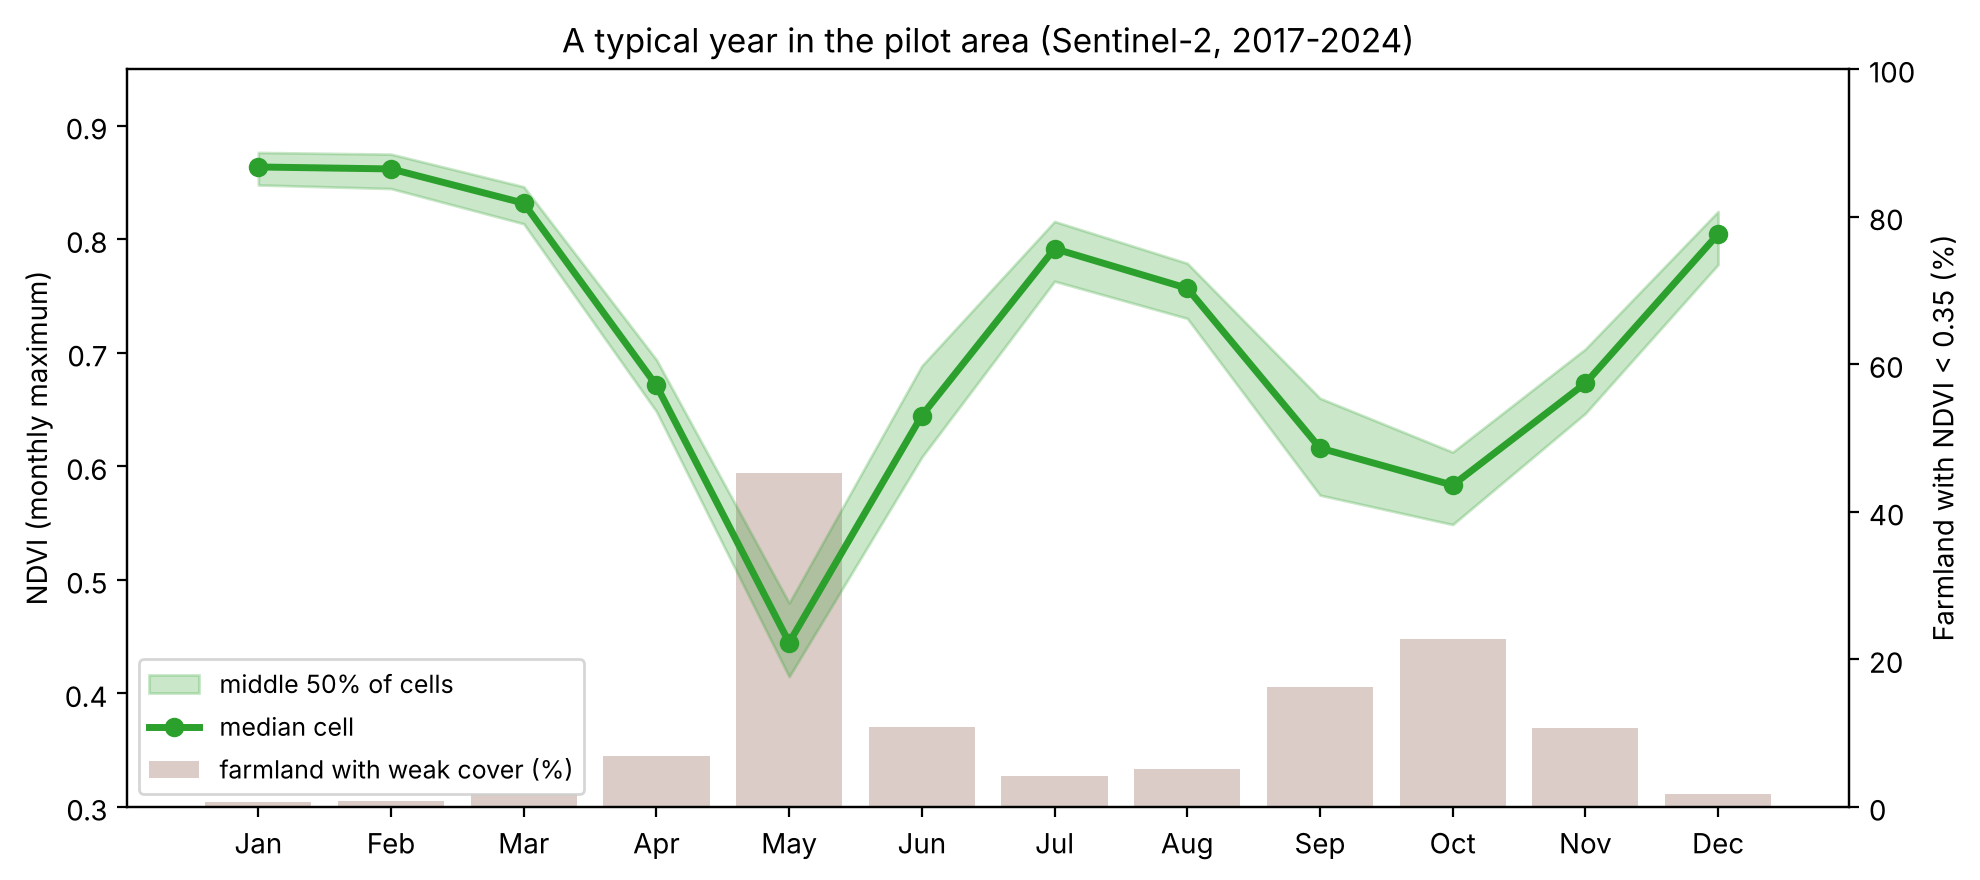

In [5]:
cm_ndvi = s2.groupby(["cell_id", "month"]).ndvi_mean.mean().unstack()      # 560 x 12
cm_low  = s2.groupby(["cell_id", "month"]).low_cover_pct.mean().unstack()
cm_bare = s2.groupby(["cell_id", "month"]).bare_pct.mean().unstack()

area = pd.DataFrame({
    "ndvi_median":   cm_ndvi.median(),
    "ndvi_p25":      cm_ndvi.quantile(0.25),
    "ndvi_p75":      cm_ndvi.quantile(0.75),
    "low_cover_pct": cm_low.mean() * 100,
    "bare_pct":      cm_bare.mean() * 100,
})
area.index = MONTHS
print(area.round(3).to_string())

fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(12)
ax.fill_between(x, area.ndvi_p25, area.ndvi_p75, alpha=0.25, color="tab:green", label="middle 50% of cells")
ax.plot(x, area.ndvi_median, "-o", color="tab:green", lw=2.5, label="median cell")
ax.set_ylabel("NDVI (monthly maximum)")
ax.set_ylim(0.3, 0.95)
ax2 = ax.twinx()
ax2.bar(x, area.low_cover_pct, alpha=0.30, color="tab:brown", label="farmland with weak cover (%)")
ax2.set_ylabel("Farmland with NDVI < 0.35 (%)")
ax2.set_ylim(0, 100)
ax.set_xticks(x, MONTHS)
ax.set_title("A typical year in the pilot area (Sentinel-2, 2017-2024)")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="lower left", fontsize=9)
ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
plt.tight_layout()
plt.savefig(FIG / "08_typical_year.png", dpi=150)
plt.show()

The picture shows **two growing seasons with two gaps between them**:

- a **winter season**, greenest in January-February
- a **spring gap**, deepest in May, when winter crops are harvested
- a **summer season**, greenest in July
- an **autumn gap**, deepest in September-October, when summer crops are harvested

This matches the Egyptian two-crop calendar: a winter crop (*shitwi*) and a summer crop (*seifi*), each followed by a short window when the field is cleared and prepared. Those two windows are where our tool's decisions happen.

The brown bars show that the spring gap is the sharpest: it is the one month when a large share of farmland is open at the same time.

## Step 3 - The typical year for every cell

Now the same thing for each of the 560 cells separately: for every cell and every month, the average over 2017-2024. We also count how many of the 8 years had a value, so later steps know how much evidence sits behind each number.

In [6]:
cnt = s2.groupby(["cell_id", "month"]).ndvi_mean.count().unstack()

scm = pd.DataFrame({
    "ndvi_clim":      cm_ndvi.stack(),
    "ndvi_min_year":  s2.groupby(["cell_id", "month"]).ndvi_mean.min(),
    "ndvi_max_year":  s2.groupby(["cell_id", "month"]).ndvi_mean.max(),
    "low_cover_clim": cm_low.stack(),
    "bare_clim":      cm_bare.stack(),
    "n_years":        cnt.stack(),
}).reset_index()
scm.columns = ["cell_id", "month"] + list(scm.columns[2:])

assert len(scm) == N_CELLS * 12
assert not scm.duplicated(["cell_id", "month"]).any()
print(f"signals_cell_month: {scm.shape}")
print(f"cell-months with all 8 years: {(scm.n_years == 8).mean()*100:.1f}%")
print(f"cell-months with fewer than 6 years: {(scm.n_years < 6).sum()}")
print(scm.head(3).round(3).to_string())

signals_cell_month: (6720, 8)
cell-months with all 8 years: 100.0%
cell-months with fewer than 6 years: 0
   cell_id  month  ndvi_clim  ndvi_min_year  ndvi_max_year  low_cover_clim  bare_clim  n_years
0        1      1      0.814          0.765          0.846           0.010      0.001        8
1        1      2      0.803          0.782          0.832           0.023      0.001        8
2        1      3      0.784          0.756          0.810           0.038      0.003        8


## Step 4 - When is each cell green, and when is it empty?

From each cell's typical year we take six signals:

| Signal | How it is computed | What it tells the farmer |
|---|---|---|
| `winter_ndvi` | mean NDVI, December to March | how strong the winter crop is |
| `summer_ndvi` | mean NDVI, June to August | how strong the summer crop is |
| `two_seasons` | both of the above are at least **0.5** | does this cell already grow two crops a year? |
| `spring_gap_month` | the month with the lowest NDVI between March and June | when the winter crop comes out |
| `autumn_gap_month` | the month with the lowest NDVI between August and November | when the summer crop comes out |
| `*_gap_open_pct` | share of the cell's farmland with NDVI below 0.35 in that gap month | how fully the field is cleared |

**Why 0.5 for `two_seasons`?** It is the same threshold we already derived and checked in notebook 04 to separate farmland from villages. We reuse it on purpose instead of inventing a new number: one threshold, one justification.

**Why search windows instead of the single lowest month of the year?** Because each cell has two dips. Searching March-June finds the spring one, and August-November finds the autumn one, without the two ever being confused.

In [7]:
sig = pd.DataFrame(index=cm_ndvi.index)
sig["winter_ndvi"] = cm_ndvi[[12, 1, 2, 3]].mean(axis=1)
sig["summer_ndvi"] = cm_ndvi[[6, 7, 8]].mean(axis=1)
sig["two_seasons"] = (sig.winter_ndvi >= FARM_T) & (sig.summer_ndvi >= FARM_T)

spring = cm_ndvi[[3, 4, 5, 6]]
autumn = cm_ndvi[[8, 9, 10, 11]]
sig["spring_gap_month"] = spring.idxmin(axis=1)
sig["spring_gap_ndvi"]  = spring.min(axis=1)
sig["autumn_gap_month"] = autumn.idxmin(axis=1)
sig["autumn_gap_ndvi"]  = autumn.min(axis=1)

def at_month(table, months):
    return pd.Series([table.at[c, mo] for c, mo in months.items()], index=months.index)

sig["spring_gap_open_pct"] = at_month(cm_low, sig.spring_gap_month) * 100
sig["autumn_gap_open_pct"] = at_month(cm_low, sig.autumn_gap_month) * 100

print("winter_ndvi :", sig.winter_ndvi.describe().round(3)[["mean", "min", "50%", "max"]].to_dict())
print("summer_ndvi :", sig.summer_ndvi.describe().round(3)[["mean", "min", "50%", "max"]].to_dict())
print(f"\ncells with two seasons: {sig.two_seasons.sum()} of {len(sig)}")
print("\nspring gap month:", {MONTHS[k-1]: int(v) for k, v in sig.spring_gap_month.value_counts().sort_index().items()})
print("autumn gap month:", {MONTHS[k-1]: int(v) for k, v in sig.autumn_gap_month.value_counts().sort_index().items()})
print(f"\nspring gap: mean NDVI {sig.spring_gap_ndvi.mean():.3f}, farmland open {sig.spring_gap_open_pct.mean():.1f}%")
print(f"autumn gap: mean NDVI {sig.autumn_gap_ndvi.mean():.3f}, farmland open {sig.autumn_gap_open_pct.mean():.1f}%")

winter_ndvi : {'mean': 0.835, 'min': 0.624, '50%': 0.841, 'max': 0.88}
summer_ndvi : {'mean': 0.725, 'min': 0.391, '50%': 0.734, 'max': 0.823}

cells with two seasons: 556 of 560

spring gap month: {'Mar': 1, 'May': 554, 'Jun': 5}
autumn gap month: {'Sep': 191, 'Oct': 367, 'Nov': 2}

spring gap: mean NDVI 0.448, farmland open 45.3%
autumn gap: mean NDVI 0.562, farmland open 24.1%


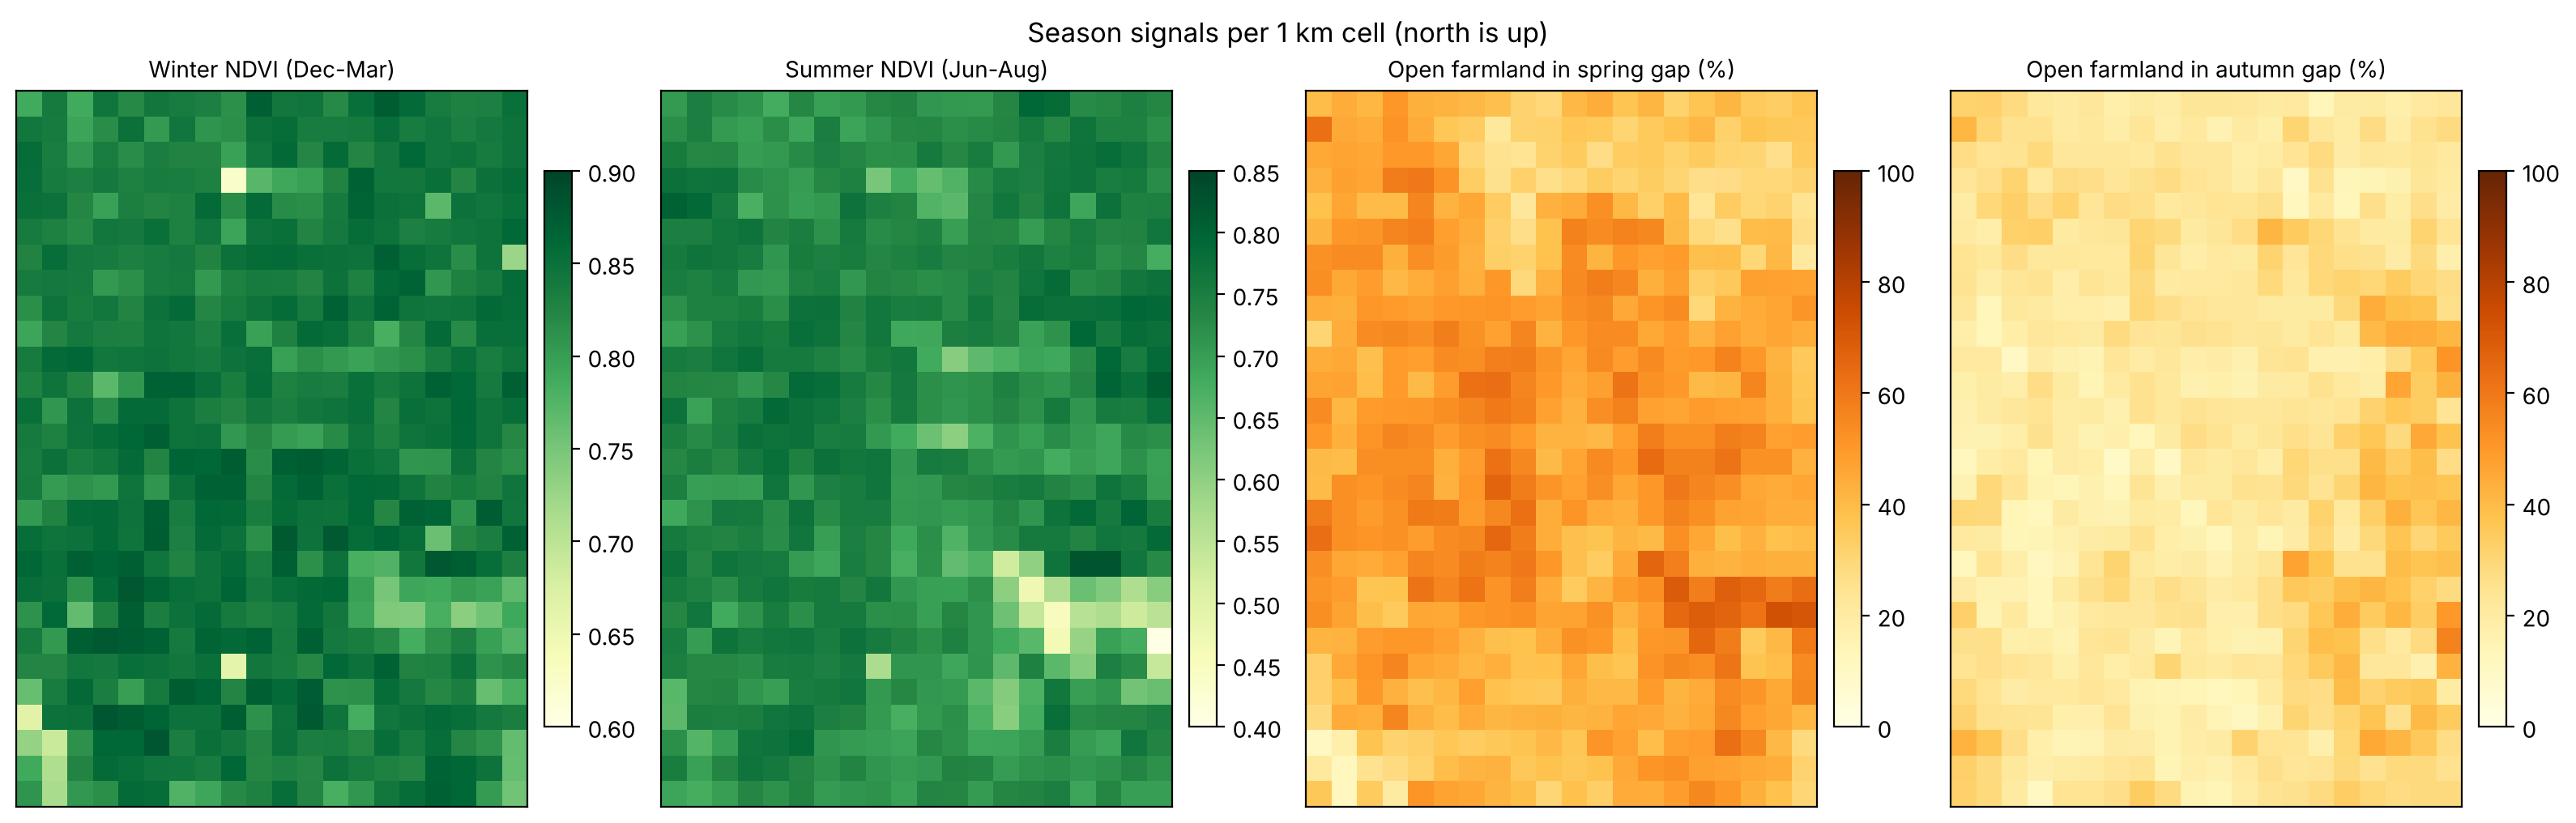

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(16, 5.2))
panels = [
    (sig.winter_ndvi,         "Winter NDVI (Dec-Mar)",            "YlGn",    (0.6, 0.9)),
    (sig.summer_ndvi,         "Summer NDVI (Jun-Aug)",            "YlGn",    (0.4, 0.85)),
    (sig.spring_gap_open_pct, "Open farmland in spring gap (%)",  "YlOrBr",  (0, 100)),
    (sig.autumn_gap_open_pct, "Open farmland in autumn gap (%)",  "YlOrBr",  (0, 100)),
]
for ax, (s, title, cmap, (lo, hi)) in zip(axes, panels):
    im = ax.imshow(to_map(s), cmap=cmap, vmin=lo, vmax=hi)
    ax.set_title(title, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
    plt.colorbar(im, ax=ax, fraction=0.05, pad=0.03)
fig.suptitle("Season signals per 1 km cell (north is up)", fontsize=12)
plt.tight_layout()
plt.savefig(FIG / "08_season_maps.png", dpi=150)
plt.show()

## Step 5 - How stable is each cell from year to year?

A cell that is green every winter is a safer bet than one that is green some winters and weak in others. We measure this with the **coefficient of variation (CV)** of the winter NDVI across the 8 years:

$$\text{CV} = \frac{\text{standard deviation over years}}{\text{mean over years}}$$

A CV of 0.02 means the winter changes by about 2% from year to year. Higher CV means a less predictable field.

We use **January to March of the same calendar year** for each year's winter, so no season is split across two years.

In [9]:
w_year = s2[s2.month.isin([1, 2, 3])].groupby(["cell_id", "year"]).ndvi_mean.mean().unstack()
s_year = s2[s2.month.isin([6, 7, 8])].groupby(["cell_id", "year"]).ndvi_mean.mean().unstack()

sig["winter_cv"] = w_year.std(axis=1) / w_year.mean(axis=1)
sig["summer_cv"] = s_year.std(axis=1) / s_year.mean(axis=1)

print("winter_cv:", sig.winter_cv.describe().round(4)[["mean", "50%", "max"]].to_dict())
print("summer_cv:", sig.summer_cv.describe().round(4)[["mean", "50%", "max"]].to_dict())
print(f"\nsummer is {sig.summer_cv.median() / sig.winter_cv.median():.1f}x less stable than winter (median cell)")

winter_cv: {'mean': 0.021, '50%': 0.019, 'max': 0.1163}
summer_cv: {'mean': 0.0376, '50%': 0.0313, 'max': 0.222}

summer is 1.6x less stable than winter (median cell)


## Step 6 - Is each cell improving or declining over 40 years?

Sentinel-2 only goes back to 2015. **Landsat** goes back to 1984 at 30 m, so it is the only way to see the long-term direction of each field.

### Which Landsat number we use, and why

In notebook 04 we found that the **yearly maximum** NDVI is biased: it rises with the number of images per year (correlation 0.72), and Landsat took far more images in recent years. A trend in that number is partly a trend in satellite coverage.

The **February-March mean** NDVI (`ndvi_winter_mean`) has almost no link to image count (correlation 0.17). February-March is also the peak of the winter crop, when fields are most comparable from year to year. So we use it.

### Two bad years, and why they change the method

The area chart below has two sharp dips: **1992** and **2002**. In both years almost every single cell drops at once. Farming does not do that - 560 separate fields do not all fail in the same winter. A whole-scene drop like this is the signature of the images themselves (haze, residual cloud or a calibration problem in the few scenes of that winter). We do not know the exact cause, so we do not delete those years. Instead we use a method they cannot bend.

An ordinary straight-line fit (least squares) is pulled hard by single extreme points. So for the trend we use the standard pair in satellite trend studies:

- **Theil-Sen slope**: the median of the slopes between every pair of years. One or two odd years barely move a median.
- **Mann-Kendall test**: asks only whether later years tend to be *higher or lower* than earlier years, not by how much. A dip counts as one "lower", however deep it is.

We still show the ordinary fit on the area chart, side by side, so the difference is visible.

### How we test each cell

For each cell we compute from its 40 yearly values:

- the **Theil-Sen slope**, written as NDVI change **per decade**
- the **Mann-Kendall p-value**: how likely a trend this consistent would be if the land were really not changing

### Why one test is not enough

We run **560 tests**, one per cell. At the usual cut-off of p < 0.05, about 28 cells would look "significant" **by chance alone**, even on land that is not changing. To avoid reporting noise as a finding, we apply the **Benjamini-Hochberg false discovery rate** correction. It turns each p-value into a q-value, and we call a cell improving or declining only if **q < 0.05**.

One limit we state openly: neighbouring cells are not independent - they share soil, water and farmers. So the 560 tests are not 560 separate pieces of evidence, and the cell classes should be read as a map pattern, not as 560 independent proofs.

correlation with image count:  yearly max = 0.723 | Feb-Mar mean = 0.169
1992: 559 of 560 cells below their neighbouring years (median drop -0.174)
2002: 557 of 560 cells below their neighbouring years (median drop -0.300)

Area trend, three ways:
                                      slope per decade              95% CI  p-value
Least squares, all 40 years                     0.0185                       0.0354
Least squares, without 1992 and 2002            0.0133                       0.0192
Theil-Sen slope + Mann-Kendall test             0.0157  +0.0024 to +0.0275   0.0144

40-year change implied by the Theil-Sen trend: +0.061 NDVI


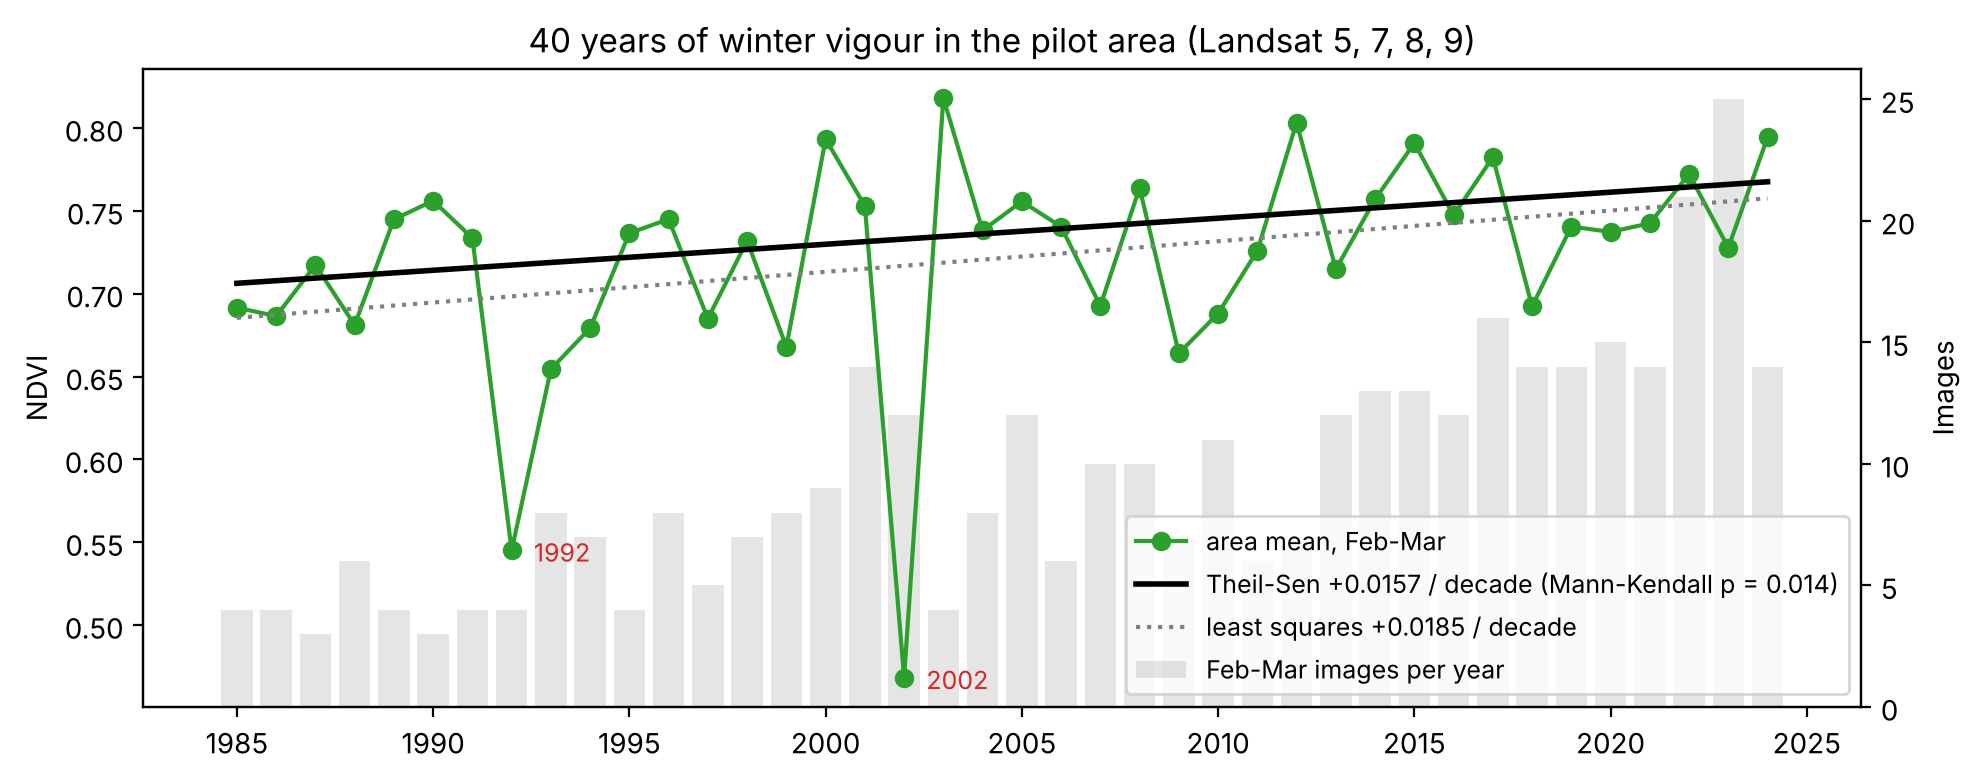

In [10]:
ya = ls.groupby("year").agg(ndvi_winter=("ndvi_winter_mean", "mean"),
                            n_winter=("n_winter", "mean"),
                            ndvi_max=("ndvi_max_mean", "mean"),
                            n_images=("n_images", "mean"))

bias_max    = np.corrcoef(ya.ndvi_max, ya.n_images)[0, 1]
bias_winter = np.corrcoef(ya.ndvi_winter, ya.n_winter)[0, 1]
print(f"correlation with image count:  yearly max = {bias_max:.3f} | Feb-Mar mean = {bias_winter:.3f}")

# How many cells drop in the two odd years? (whole-scene vs field-level)
for y in [1992, 2002]:
    near = ls[ls.year.between(y - 3, y + 3) & (ls.year != y)].groupby("cell_id").ndvi_winter_mean.mean()
    d = ls[ls.year == y].set_index("cell_id").ndvi_winter_mean - near
    print(f"{y}: {(d < 0).sum()} of 560 cells below their neighbouring years (median drop {d.median():+.3f})")

ols  = stats.linregress(ya.index, ya.ndvi_winter)
ya2  = ya.drop([1992, 2002])
ols2 = stats.linregress(ya2.index, ya2.ndvi_winter)
ts   = stats.theilslopes(ya.ndvi_winter, ya.index)
mk   = stats.kendalltau(ya.index, ya.ndvi_winter)

robust = pd.DataFrame({
    "slope per decade": [ols.slope*10, ols2.slope*10, ts.slope*10],
    "95% CI":           ["", "", f"{ts.low_slope*10:+.4f} to {ts.high_slope*10:+.4f}"],
    "p-value":          [ols.pvalue, ols2.pvalue, mk.pvalue],
}, index=["Least squares, all 40 years",
          "Least squares, without 1992 and 2002",
          "Theil-Sen slope + Mann-Kendall test"])
print("\nArea trend, three ways:")
print(robust.round(4).to_string())
print(f"\n40-year change implied by the Theil-Sen trend: {ts.slope*39:+.3f} NDVI")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(ya.index, ya.ndvi_winter, "o-", color="tab:green", label="area mean, Feb-Mar")
ax.plot(ya.index, ts.intercept + ts.slope * ya.index, "-", color="black", lw=2,
        label=f"Theil-Sen {ts.slope*10:+.4f} / decade (Mann-Kendall p = {mk.pvalue:.3f})")
ax.plot(ya.index, ols.intercept + ols.slope * ya.index, ":", color="gray",
        label=f"least squares {ols.slope*10:+.4f} / decade")
for y in [1992, 2002]:
    ax.annotate(str(y), (y, ya.ndvi_winter[y]), textcoords="offset points", xytext=(8, -4), fontsize=9, color="tab:red")
ax.set_ylabel("NDVI")
ax2 = ax.twinx()
ax2.bar(ya.index, ya.n_winter, alpha=0.2, color="gray", label="Feb-Mar images per year")
ax2.set_ylabel("Images")
ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="lower right", fontsize=9)
ax.set_title("40 years of winter vigour in the pilot area (Landsat 5, 7, 8, 9)")
plt.tight_layout()
plt.savefig(FIG / "08_landsat_40yr.png", dpi=150)
plt.show()

In [11]:
rows = []
for cid, g in ls.groupby("cell_id"):
    g = g.dropna(subset=["ndvi_winter_mean"])
    slope = stats.theilslopes(g.ndvi_winter_mean, g.year).slope     # robust slope
    p     = stats.kendalltau(g.year, g.ndvi_winter_mean).pvalue    # Mann-Kendall test
    rows.append((cid, slope * 10, p, len(g)))
tr = pd.DataFrame(rows, columns=["cell_id", "ls_trend_per_decade", "ls_trend_p", "ls_n_years"]).set_index("cell_id")
tr["ls_trend_q"] = stats.false_discovery_control(tr.ls_trend_p, method="bh")
tr["ls_trend_class"] = np.select(
    [(tr.ls_trend_q < 0.05) & (tr.ls_trend_per_decade > 0),
     (tr.ls_trend_q < 0.05) & (tr.ls_trend_per_decade < 0)],
    ["improving", "declining"], default="stable")

raw_pos = ((tr.ls_trend_p < 0.05) & (tr.ls_trend_per_decade > 0)).sum()
raw_neg = ((tr.ls_trend_p < 0.05) & (tr.ls_trend_per_decade < 0)).sum()
print(f"years per cell: {tr.ls_n_years.min()}-{tr.ls_n_years.max()}")
print(f"\nwithout correction (p < 0.05): improving {raw_pos}, declining {raw_neg}  (about 28 expected by chance alone)")
print("with FDR correction (q < 0.05):", tr.ls_trend_class.value_counts().to_dict())
print(f"\nslope per decade, all cells: median {tr.ls_trend_per_decade.median():+.4f}, "
      f"range {tr.ls_trend_per_decade.min():+.4f} to {tr.ls_trend_per_decade.max():+.4f}")
print(f"cells with a positive slope (any size): {(tr.ls_trend_per_decade > 0).sum()} of {len(tr)}")
sig = sig.join(tr)

years per cell: 37-40

without correction (p < 0.05): improving 284, declining 9  (about 28 expected by chance alone)
with FDR correction (q < 0.05): {'stable': 337, 'improving': 219, 'declining': 4}

slope per decade, all cells: median +0.0140, range -0.0379 to +0.0540
cells with a positive slope (any size): 507 of 560


### What does "declining" actually mean here?

A falling winter NDVI could mean two very different things:

1. **The soil or water is getting worse**, so the same farmland grows weaker crops. This is what a farmer needs to be warned about.
2. **A village is growing into the cell.** Houses replace fields, and the pixels at the edge of the village mix roofs with crops, which pulls NDVI down. The farmland that is left may be perfectly healthy.

Landsat can tell these apart, because notebook 04 also recorded `farm_pct` - the share of each cell that is farmland - for every year since 1985. If a declining cell also **lost farmland**, the cause is the village. If it **kept its farmland**, the decline is in the crops themselves.

We compare each cell's farmland share in the first decade (1985-1994) with the last decade (2015-2024).

In [12]:
early = ls[ls.year.between(1985, 1994)].groupby("cell_id").farm_pct.mean()
late  = ls[ls.year.between(2015, 2024)].groupby("cell_id").farm_pct.mean()
sig["ls_farm_1985_94"]    = early
sig["ls_farm_2015_24"]    = late
sig["ls_farm_pct_change"] = late - early

dec = sig[sig.ls_trend_class == "declining"][
    ["ls_trend_per_decade", "ls_trend_q", "ls_farm_1985_94", "ls_farm_2015_24", "ls_farm_pct_change"]]
print("The declining cells:")
print(dec.round(4).to_string())

r_fc = np.corrcoef(sig.ls_farm_pct_change, sig.ls_trend_per_decade)[0, 1]
print(f"\ncorrelation, all 560 cells: farmland change vs NDVI trend = {r_fc:+.3f}")
print(f"cells that lost more than 20 points of farmland since 1985-94: {(sig.ls_farm_pct_change < -0.20).sum()}")
print("mean farmland change by class:",
      sig.groupby("ls_trend_class").ls_farm_pct_change.mean().round(3).to_dict())

lost = (sig.ls_trend_class == "declining") & (sig.ls_farm_pct_change < -0.10)
kept = (sig.ls_trend_class == "declining") & ~lost
print(f"\ndeclining because a village grew in : {lost.sum()} cells {sig.index[lost].tolist()}")
print(f"declining with its farmland intact  : {kept.sum()} cells {sig.index[kept].tolist()}")

The declining cells:
         ls_trend_per_decade  ls_trend_q  ls_farm_1985_94  ls_farm_2015_24  ls_farm_pct_change
cell_id                                                                                       
69                   -0.0379      0.0036           0.3223           0.1594             -0.1629
70                   -0.0137      0.0351           0.7504           0.4498             -0.3007
449                  -0.0210      0.0191           0.2552           0.1065             -0.1487
501                  -0.0214      0.0093           0.9536           0.9312             -0.0224

correlation, all 560 cells: farmland change vs NDVI trend = +0.393
cells that lost more than 20 points of farmland since 1985-94: 2
mean farmland change by class: {'declining': -0.159, 'improving': 0.022, 'stable': -0.007}

declining because a village grew in : 3 cells [69, 70, 449]
declining with its farmland intact  : 1 cells [501]


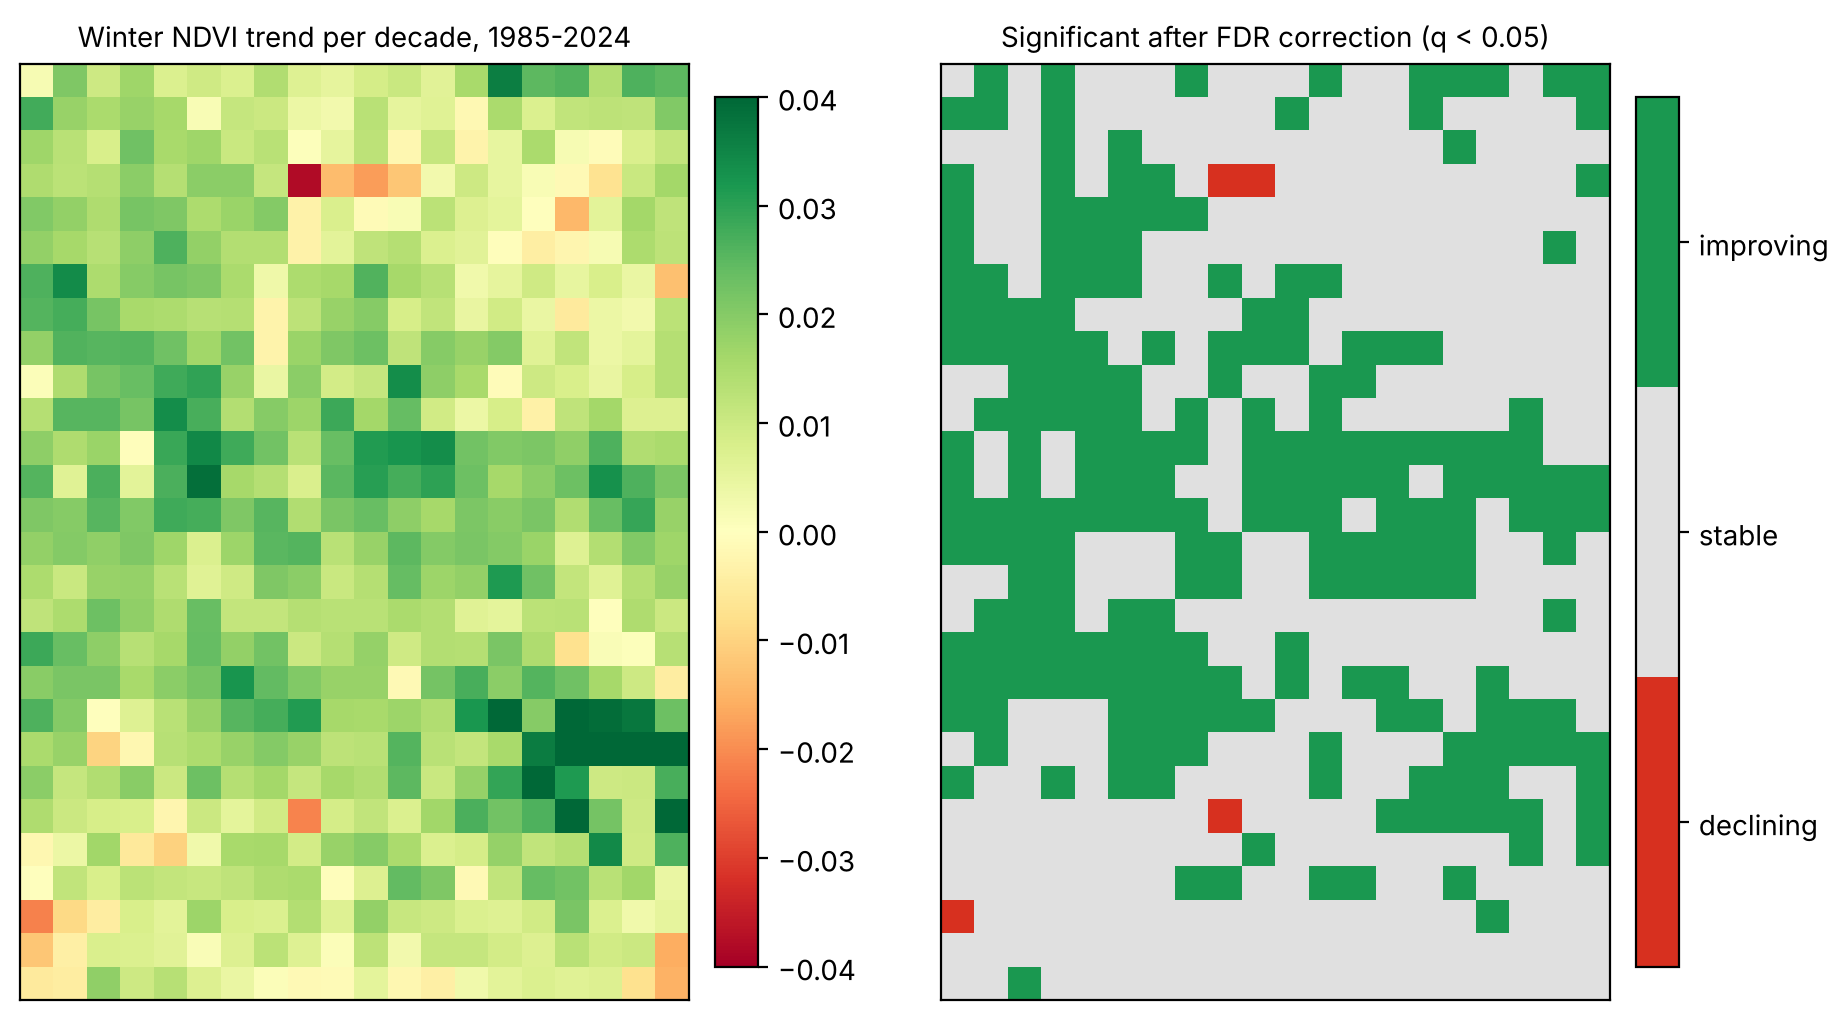

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5.2))
im = axes[0].imshow(to_map(sig.ls_trend_per_decade), cmap="RdYlGn", vmin=-0.04, vmax=0.04)
axes[0].set_title("Winter NDVI trend per decade, 1985-2024", fontsize=10)
plt.colorbar(im, ax=axes[0], fraction=0.05, pad=0.03)

cls_num = sig.ls_trend_class.map({"declining": -1, "stable": 0, "improving": 1})
from matplotlib.colors import ListedColormap
im2 = axes[1].imshow(to_map(cls_num), cmap=ListedColormap(["#d7301f", "#e0e0e0", "#1a9850"]), vmin=-1.5, vmax=1.5)
axes[1].set_title("Significant after FDR correction (q < 0.05)", fontsize=10)
cb = plt.colorbar(im2, ax=axes[1], fraction=0.05, pad=0.03, ticks=[-1, 0, 1])
cb.ax.set_yticklabels(["declining", "stable", "improving"])
for a in axes: a.set_xticks([]); a.set_yticks([])
plt.tight_layout()
plt.savefig(FIG / "08_landsat_trend_map.png", dpi=150)
plt.show()

## Step 7 - Rain, heat and water need, month by month

These datasets have **one value for the whole area per month**, so these signals are per month, not per cell (see notebook 03 for why SMAP cannot be split into 1 km cells: the instrument sees about 36 km).

| Signal | Source | Meaning |
|---|---|---|
| `rain_mm`, `rain_days` | GPM IMERG | water from the sky |
| `t_max_c`, `t_mean_c`, `t_min_c` | NASA POWER | heat |
| `rh_pct`, `solar_mj_m2_day` | NASA POWER | humidity and sunlight |
| `wilting_frac_rainfed` | SMAP L4 | share of land that would be at wilting point **without irrigation** |

As explained in notebook 03, SMAP L4 does not see irrigation by design. So `wilting_frac_rainfed` is not "how dry the fields are". It is **how much the land depends on irrigation in that month**. We use it as our irrigation-need signal.

### A cross-check between two NASA missions

If `wilting_frac_rainfed` really tracks water from rain, it must go **down when GPM sees more rain**. And because soil holds water, rain in one month should still lower wilting in the **next** month. GPM (precipitation radar and radiometers) and SMAP (L-band radiometer plus a land model) are different missions with different instruments, so agreement between them is real evidence.

In [14]:
gpm  = m.groupby(["year", "month"])[["rain_mm", "rain_days", "max_day_rain_mm"]].first()
smap = m.groupby(["year", "month"])[["wilting_frac_rainfed", "sm_rootzone_rainfed_m3m3"]].first()
pwr  = m.groupby(["year", "month"])[["t_max_c", "t_mean_c", "t_min_c", "rh_pct",
                                      "solar_mj_m2_day", "power_rain_mm"]].first()
wm = gpm.join(smap).join(pwr).reset_index().sort_values(["year", "month"])
assert len(wm) == N_MONTHS

wm["rain_prev_month"] = wm.rain_mm.shift(1)
same = stats.spearmanr(wm.rain_mm, wm.wilting_frac_rainfed)
lag  = stats.spearmanr(wm.rain_prev_month[1:], wm.wilting_frac_rainfed[1:])
sm_r = stats.spearmanr(wm.rain_mm, wm.sm_rootzone_rainfed_m3m3)
two  = stats.pearsonr(wm.rain_mm, wm.power_rain_mm)

print("Cross-check GPM rain vs SMAP (108 months, Spearman):")
print(f"  rain this month  vs wilting this month : rho = {same.statistic:+.3f}  (p = {same.pvalue:.1e})")
print(f"  rain last month  vs wilting this month : rho = {lag.statistic:+.3f}  (p = {lag.pvalue:.1e})")
print(f"  rain this month  vs root-zone moisture : rho = {sm_r.statistic:+.3f}  (p = {sm_r.pvalue:.1e})")
print(f"\nGPM rain vs NASA POWER rain (Pearson): r = {two.statistic:.3f}")

yr = wm.groupby("year").rain_mm.sum()
print(f"\nannual rain (GPM): mean {yr.mean():.0f} mm, driest year {yr.min():.0f} mm ({yr.idxmin()}), wettest {yr.max():.0f} mm ({yr.idxmax()})")
print(f"share of the year's rain falling November-March: "
      f"{wm[wm.month.isin([11,12,1,2,3])].rain_mm.sum() / wm.rain_mm.sum() * 100:.1f}%")

Cross-check GPM rain vs SMAP (108 months, Spearman):
  rain this month  vs wilting this month : rho = -0.759  (p = 1.9e-21)
  rain last month  vs wilting this month : rho = -0.814  (p = 1.5e-26)
  rain this month  vs root-zone moisture : rho = +0.756  (p = 3.1e-21)

GPM rain vs NASA POWER rain (Pearson): r = 0.527

annual rain (GPM): mean 110 mm, driest year 43 mm (2017), wettest 257 mm (2020)
share of the year's rain falling November-March: 90.6%


GPM and NASA POWER rain agree only moderately. That is expected: NASA POWER rain comes from the MERRA-2 weather model, while GPM is built from satellite observations of precipitation. For rain we use **GPM** as our primary source, as planned in `data_sources.md`, and keep POWER rain in the table only for transparency.

 month name  rain_mm  rain_days  t_max_c  t_mean_c  t_min_c  rh_pct  solar_mj_m2_day  wilting_frac_rainfed  sm_rootzone_rainfed_m3m3  irrigation_need_rank  ndvi_area_median  farmland_open_pct
     1  Jan    28.17       4.67    19.15     13.22     8.94   69.68            10.90                  0.68                      0.15                    11              0.86               0.66
     2  Feb    14.20       3.11    20.89     14.17     9.22   69.16            14.09                  0.67                      0.15                    12              0.86               0.77
     3  Mar    20.36       3.00    24.11     16.59    10.85   62.85            18.69                  0.72                      0.14                    10              0.83               1.69
     4  Apr     4.53       1.11    29.16     20.49    13.49   57.32            23.45                  0.82                      0.13                     8              0.67               6.90
     5  May     1.00       0.22    33.77

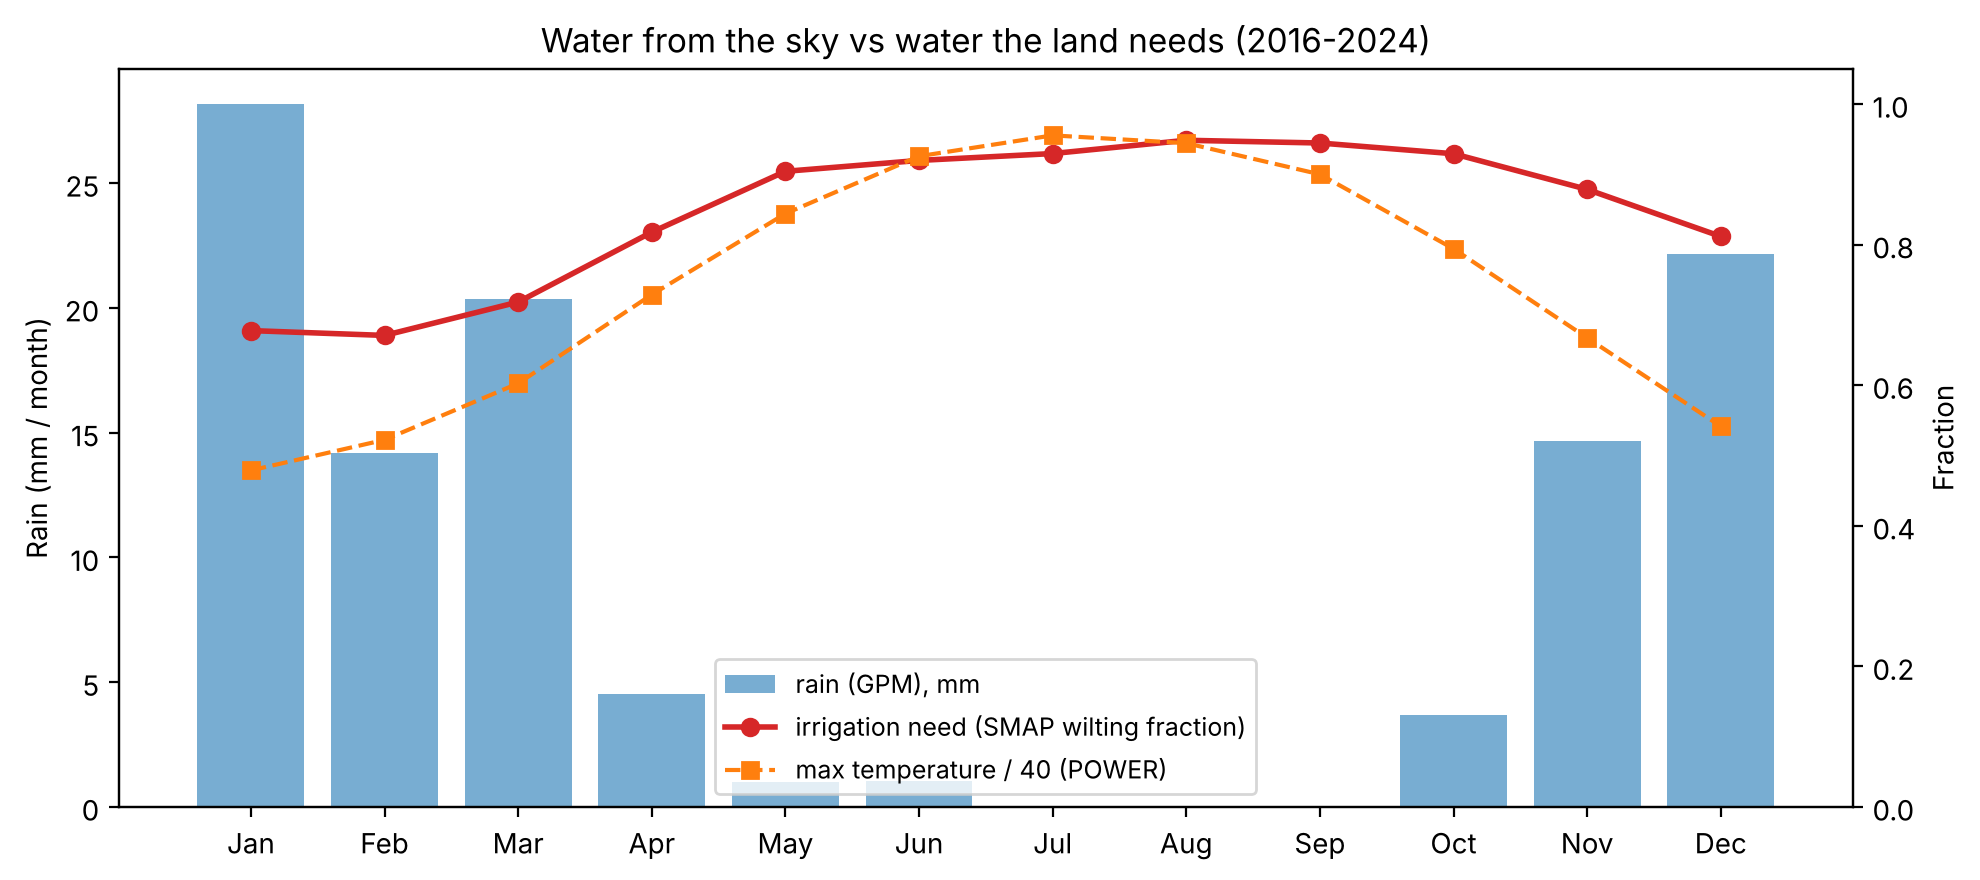

In [15]:
sam = wm.groupby("month").agg(
    rain_mm=("rain_mm", "mean"),
    rain_days=("rain_days", "mean"),
    t_max_c=("t_max_c", "mean"),
    t_mean_c=("t_mean_c", "mean"),
    t_min_c=("t_min_c", "mean"),
    rh_pct=("rh_pct", "mean"),
    solar_mj_m2_day=("solar_mj_m2_day", "mean"),
    wilting_frac_rainfed=("wilting_frac_rainfed", "mean"),
    sm_rootzone_rainfed_m3m3=("sm_rootzone_rainfed_m3m3", "mean"),
)
sam["irrigation_need_rank"] = sam.wilting_frac_rainfed.rank(ascending=False, method="min").astype(int)
sam["ndvi_area_median"] = area.ndvi_median.values
sam["farmland_open_pct"] = area.low_cover_pct.values
sam = sam.reset_index()

show = sam.copy(); show.insert(1, "name", MONTHS)
print(show.round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(12)
ax.bar(x, sam.rain_mm, color="tab:blue", alpha=0.6, label="rain (GPM), mm")
ax.set_ylabel("Rain (mm / month)")
ax2 = ax.twinx()
ax2.plot(x, sam.wilting_frac_rainfed, "o-", color="tab:red", lw=2, label="irrigation need (SMAP wilting fraction)")
ax2.plot(x, sam.t_max_c / 40, "s--", color="tab:orange", lw=1.5, label="max temperature / 40 (POWER)")
ax2.set_ylim(0, 1.05)
ax2.set_ylabel("Fraction")
ax.set_xticks(x, MONTHS)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="lower center", fontsize=9)
ax.set_title("Water from the sky vs water the land needs (2016-2024)")
plt.tight_layout()
plt.savefig(FIG / "08_water_by_month.png", dpi=150)
plt.show()

## Step 8 - How much can we trust each cell?

Every recommendation our tool makes should say how much evidence sits behind it. Here we record three facts per cell:

| Signal | Meaning |
|---|---|
| `farm_pct` | share of the cell that is farmland (2017-2024 mean). A cell that is mostly village should not get a crop recommendation. |
| `is_farm_cell` | `farm_pct` is at least 0.5, the same 0.5 threshold used everywhere else |
| `valid_pct_mean` | average share of the cell that had a cloud-free view each month |
| `ndvi_missing_months` | number of the 96 months (2017-2024) with no clear view at all |

We expect `ndvi_missing_months` to be zero almost everywhere: Step 1 showed that the months with no clear view were in 2016, which we already set aside. We keep the column anyway, so that if the pipeline is re-run with new years, a cloudy year would show up here instead of passing silently.

In [16]:
sig["farm_pct"]            = s2.groupby("cell_id").farm_pct.mean()
sig["is_farm_cell"]        = sig.farm_pct >= FARM_T
sig["valid_pct_mean"]      = s2.groupby("cell_id").valid_pct.mean()
sig["ndvi_missing_months"] = s2.groupby("cell_id").ndvi_mean.apply(lambda s: int(s.isna().sum()))

print(f"cells that are mostly farmland: {sig.is_farm_cell.sum()} of {len(sig)}")
print(f"cells that are mostly not farmland: {(~sig.is_farm_cell).sum()}")
print(f"\nvalid_pct_mean: median {sig.valid_pct_mean.median():.3f}, lowest {sig.valid_pct_mean.min():.3f}")
print("missing NDVI months per cell:", sig.ndvi_missing_months.describe().round(1)[["mean", "50%", "max"]].to_dict())
print(f"cells with zero missing months: {(sig.ndvi_missing_months == 0).sum()}")

print("\nnon-farm cells:")
print(sig.loc[~sig.is_farm_cell, ["farm_pct", "winter_ndvi", "summer_ndvi", "two_seasons"]].round(3).to_string())

cells that are mostly farmland: 556 of 560
cells that are mostly not farmland: 4

valid_pct_mean: median 1.000, lowest 0.992
missing NDVI months per cell: {'mean': 0.0, '50%': 0.0, 'max': 0.0}
cells with zero missing months: 560

non-farm cells:
         farm_pct  winter_ndvi  summer_ndvi  two_seasons
cell_id                                                 
69          0.154        0.624        0.624         True
70          0.427        0.772        0.679         True
449         0.100        0.662        0.570         True
481         0.479        0.664        0.652         True


## Step 9 - Assemble and save

We join the cell position, run final checks, and write the three files. Every check below must say **PASS** before anything downstream is allowed to read these files.

In [17]:
out = (grid[["cell_id", "row", "col", "lat", "lon"]].set_index("cell_id")
       .join(sig, how="left").reset_index())

col_order = ["cell_id", "row", "col", "lat", "lon",
             "farm_pct", "is_farm_cell",
             "winter_ndvi", "summer_ndvi", "two_seasons",
             "spring_gap_month", "spring_gap_ndvi", "spring_gap_open_pct",
             "autumn_gap_month", "autumn_gap_ndvi", "autumn_gap_open_pct",
             "winter_cv", "summer_cv",
             "ls_trend_per_decade", "ls_trend_p", "ls_trend_q", "ls_trend_class", "ls_n_years",
             "ls_farm_1985_94", "ls_farm_2015_24", "ls_farm_pct_change",
             "valid_pct_mean", "ndvi_missing_months"]
out = out[col_order]

checks = {
    "signals_cell has 560 rows":           len(out) == N_CELLS,
    "cell_id unique":                      out.cell_id.is_unique,
    "no missing value in signals_cell":    not out.isna().any().any(),
    "gap months in their search windows":  out.spring_gap_month.between(3, 6).all() and out.autumn_gap_month.between(8, 11).all(),
    "NDVI signals inside [-1, 1]":         out[["winter_ndvi", "summer_ndvi", "spring_gap_ndvi", "autumn_gap_ndvi"]].abs().le(1).all().all(),
    "q-values never below p-values":       (out.ls_trend_q >= out.ls_trend_p - 1e-12).all(),
    "signals_cell_month has 6,720 rows":   len(scm) == N_CELLS * 12,
    "signals_area_month has 12 rows":      len(sam) == 12 and sam.month.tolist() == list(range(1, 13)),
}
for k, v in checks.items():
    print(f"  {'PASS' if v else 'FAIL'}  {k}")
assert all(checks.values()), "a check failed - do not use these files"

out.to_csv(P / "signals_cell.csv", index=False)
scm.to_csv(P / "signals_cell_month.csv", index=False)
sam.to_csv(P / "signals_area_month.csv", index=False)

for f in ["signals_cell.csv", "signals_cell_month.csv", "signals_area_month.csv"]:
    d = pd.read_csv(P / f)
    print(f"\nsaved {f:26s} {d.shape}")
print("\nfigures:", sorted(p.name for p in FIG.glob("08_*.png")))

  PASS  signals_cell has 560 rows
  PASS  cell_id unique
  PASS  no missing value in signals_cell
  PASS  gap months in their search windows
  PASS  NDVI signals inside [-1, 1]
  PASS  q-values never below p-values
  PASS  signals_cell_month has 6,720 rows
  PASS  signals_area_month has 12 rows

saved signals_cell.csv           (560, 28)

saved signals_cell_month.csv     (6720, 8)

saved signals_area_month.csv     (12, 13)

figures: ['08_landsat_40yr.png', '08_landsat_trend_map.png', '08_season_maps.png', '08_typical_year.png', '08_water_by_month.png']


## Conclusion

All checks passed. We turned 60,480 rows x 60 columns into three small tables that answer the farmer's three questions, plus five figures. Every number below comes from the outputs above.

### 1. We set 2016 aside, with evidence

2016 was lower than the lowest of the other eight years in **8 of 12 months** (October by 6.4 standard deviations). It was also the **only** year with cell-months that had no clear view at all: all **467** such cell-months in the whole dataset are in 2016, and none are in 2017-2024. Both symptoms fit fewer satellite passes before Sentinel-2B; neither fits a change in farming. Sentinel-2 signals therefore use 2017-2024. 2016 stays in the master table untouched.

### 2. When is the field empty? Two clear windows

| | Winter season | **Spring gap** | Summer season | **Autumn gap** |
|---|---|---|---|---|
| Peak / low month | Jan-Feb | **May** | Jul | **Sep-Oct** |
| Median NDVI | 0.86 | **0.45** | 0.79 | **0.58** (Oct) |
| Farmland open (NDVI < 0.35) | under 1% | **45%** | 4% | **23%** (Oct) |

- **556 of 560 cells** grow two crops a year. The other 4 are mostly village (see section 5).
- The spring gap falls in **May in 554 of 560 cells**. It is sharp and the same everywhere: almost half of all farmland is open in the same month.
- The autumn gap is spread out: **October in 367 cells, September in 191**. Summer crops come out over a longer period, so the decision window is wider but less synchronised.

These two windows are where our tool makes its decisions.

### 3. Which season is riskier? Summer

Year-to-year variation (CV) is **0.019 in winter** and **0.031 in summer** for the median cell: the summer crop is **1.6x less predictable**. Section 4 shows why.

### 4. How much water does each month need? Almost all of it comes from the Nile

| | Nov-Mar | Apr-Oct |
|---|---|---|
| Share of the year's rain | **90.6%** | 9.4% |
| Irrigation need (SMAP wilting fraction) | 0.67-0.88 | 0.82-**0.95** |
| Max temperature | 19-27 C | 29-**38 C** |

Rain averages only **110 mm a year** (from 43 mm in 2017 to 257 mm in 2020), and **July, August and September get none**. Irrigation need peaks in **August (0.95)** and is lowest in **February (0.67)**.

This explains section 3. The winter crop gets a little help from rain; the summer crop is grown entirely on irrigation water through the hottest months. Any shortage of canal water hits the summer crop first.

**Two NASA missions confirm each other.** GPM rain and SMAP wilting move in opposite directions (Spearman **rho = -0.76**, p = 2e-21), and the link is even stronger when rain is one month earlier (**rho = -0.81**, p = 2e-26): the soil remembers last month's rain. Two different instruments on two different missions telling the same physical story is strong support for using SMAP as our irrigation-need signal.

GPM and NASA POWER rain agree only moderately (r = 0.53). POWER rain comes from a weather model; GPM is built from satellite observations of precipitation. We use GPM.

### 5. Is the land getting better or worse? Better, almost everywhere

We used the February-March mean, not the yearly maximum, because the maximum is biased by the number of images (correlation 0.72 vs 0.17).

Two winters, **1992 and 2002**, dropped in 559 and 557 of the 560 cells at once. Whole-scene drops like that come from the images, not from farming, so we checked that they were not creating the trend:

| Method | Trend per decade | p-value |
|---|---|---|
| Least squares, all 40 years | +0.0185 | 0.035 |
| Least squares, without 1992 and 2002 | +0.0133 | 0.019 |
| **Theil-Sen + Mann-Kendall** (robust) | **+0.0157** (95% CI +0.0024 to +0.0275) | **0.014** |

**The area is greening under all three methods**, and the robust confidence interval stays above zero. Our best estimate is **+0.016 NDVI per decade**, about **+0.06** over 40 years. The ordinary fit slightly overstated it, because the 1992 dip sits early in the record.

Per cell, **507 of 560** have a positive slope. Testing all 560 cells naively (p < 0.05) would call 284 improving and 9 declining - but about 28 would pass that test by chance alone. After the Benjamini-Hochberg false discovery rate correction:

| Class | Cells |
|---|---|
| Improving | **219** |
| Stable | **337** |
| Declining | **4** |

**And "declining" mostly does not mean what it seems.** Three of the four declining cells **lost a large share of their farmland** since the 1980s:

| Cell | Farmland 1985-94 | Farmland 2015-24 | Trend per decade |
|---|---|---|---|
| 69 | 32% | 16% | -0.038 |
| 70 | 75% | 45% | -0.014 |
| 449 | 26% | 11% | -0.021 |
| **501** | **95%** | **93%** | **-0.021** |

In cells 69, 70 and 449 the NDVI fell because a village grew into the fields, not because the soil got worse. Across all cells, losing farmland and losing NDVI go together (r = +0.39).

Only **cell 501** is declining with its farmland intact. That is the one cell where the crops themselves are getting weaker. Our tool should flag it and not recommend a demanding crop there without a field check.

This changes what our tool should say. A farmer in cell 69 does not need a warning about soil. The farmland around them is being built on.

### 6. How much can we trust each cell?

Data quality is very high: median clear share **1.000**, lowest **0.992**, and **zero** cell-months without a clear view in 2017-2024. **4 cells** are mostly not farmland (`is_farm_cell = False`) and should not receive a crop recommendation.

### What this hands to the next step

| File | Shape | Used for |
|---|---|---|
| `signals_cell.csv` | 560 x 28 | each cell's seasons, gaps, stability, 40-year trend, farmland loss, data quality |
| `signals_cell_month.csv` | 6,720 x 8 | each cell's typical year, month by month |
| `signals_area_month.csv` | 12 x 13 | rain, heat and irrigation need, month by month |

Notebook 09 builds the other half: what each candidate crop **needs** - when it is planted, how long it grows, how much water and heat it can take. Notebook 10 matches the two.